# Notebook 04: MHIST — Adquisición Regulada y EDA de Referencia
**Dataset:** MHIST — Minimalist Histopathology Image Analysis Dataset  
**Portal Oficial (Registro DUA):** https://bmirds.github.io/MHIST/  
**Artículo:** Wei et al. (2021) — *A Petri Dish for Histopathology Image Analysis* (AIME 2021, arXiv:2101.12355)

---
## Descripción

MHIST contiene **3,152 imágenes** FFPE de **224×224 px** de pólipos colorrectales evaluadas por **7 patólogos gastrointestinales**.
De acuerdo con el **Table 1 oficial de Wei et al. (2021)**, las particiones oficiales son:

| Split | Imágenes | HP (Benigno) | SSA (Precancerígeno) | % SSA |
|-------|----------|--------------|----------------------|-------|
| Train | 2,175 | 1,545 | 630 | 28.97% |
| Test | 977 | 617 | 360 | 36.85% |
| **Total** | **3,152** | **2,162** | **990** | **31.41%** |

> **Nota sobre descarga:** Dartmouth BMIRDS exige completar el formulario de **Dataset Research Use Agreement (DUA)** en `https://bmirds.github.io/MHIST/` para recibir `annotations.csv` e `images.zip` (333 MB). Si dichos archivos aún no se encuentran en `data_samples/mhist/`, este notebook opera en **Modo Referencia Bibliográfica** (sin inventar registros falsos).


In [1]:
# ============================================================
# IMPORTS Y CONFIGURACIÓN
# ============================================================
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
sns.set_theme(style='whitegrid')

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SAVE_DIR = BASE_DIR / 'data_samples' / 'mhist'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

TABLAS_DIR = BASE_DIR / 'tablas'
TABLAS_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = BASE_DIR / 'figures' / '04_MHIST'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Helper para guardar subplots individuales
def guardar_subplots_individuales(fig, nombre_base, fig_dir, dpi=150):
    """Guarda cada panel principal visible sin duplicar ejes gemelos o colorbars."""
    axes = []
    pos_vistas = set()
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        if ax.get_subplotspec() is None:
            continue
        pos = tuple(round(v, 4) for v in ax.get_position().bounds)
        if pos not in pos_vistas:
            pos_vistas.add(pos)
            axes.append(ax)
    for i, ax in enumerate(axes):
        extent = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        bbox = extent.expanded(1.18, 1.18)
        outpath = Path(fig_dir) / f'{nombre_base}_panel_{i+1}.png'
        fig.savefig(outpath, bbox_inches=bbox, dpi=dpi)
    print(f'✅ {len(axes)} paneles individuales guardados en: {fig_dir}')

print(f'✅ Directorio de datos:   {SAVE_DIR}')
print(f'✅ Directorio de tablas:  {TABLAS_DIR}')
print(f'✅ Directorio de figuras: {FIG_DIR}')


✅ Directorio de datos:   c:\Universidad\Magister\20 Noviembre Reunion\data_samples\mhist
✅ Directorio de tablas:  c:\Universidad\Magister\20 Noviembre Reunion\tablas
✅ Directorio de figuras: c:\Universidad\Magister\20 Noviembre Reunion\figures\04_MHIST


---
### 📌 ¿Qué hace esta celda?
Carga las librerías necesarias para el análisis del dataset MHIST, establece la configuración de visualización global y crea las carpetas destinadas a los datos (`../data_samples/mhist`), tablas Excel (`../tablas`) y figuras específicas del dataset (`../figures/04_MHIST`). Incorpora además la función estandarizada para guardar individualmente cada panel de figuras compuestas.

### ⚙️ ¿Cómo funciona?
- **`pathlib.Path`**: Inicializa las carpetas del proyecto con `.mkdir(parents=True, exist_ok=True)`, garantizando compatibilidad multiplataforma en sistemas Windows/Linux.
- **Configuración gráfica**: Define un tamaño predeterminado de 14×6 pulgadas y tema `whitegrid` para gráficos claros y legibles.
- **Función `guardar_subplots_individuales`**: Itera por cada eje visible del objeto figura, calcula el recuadro delimitador transformado por DPI con un 20% de margen adicional (`bbox.expanded(1.2, 1.2)`) y guarda cada panel en formato PNG a 150 DPI.

### 📊 Flujo de Configuración
```text
┌─────────────────────────┐     ┌─────────────────────────┐     ┌─────────────────────────┐
│ Importar Librerías      │ ──> │ Crear Directorios       │ ──> │ Helper Subplots         │
│ (pandas, plt, sns, Path)│     │ data, tablas, 04_MHIST  │     │ Paneles Individuales    │
└─────────────────────────┘     └─────────────────────────┘     └─────────────────────────┘
```
---


In [2]:
# ============================================================
# VERIFICACIÓN DE ARCHIVOS OFICIALES DE MHIST (BAJO DUA BMIRDS)
# ============================================================
ANNOTATIONS_PATH = SAVE_DIR / 'annotations.csv'
IMAGES_DIR = SAVE_DIR / 'images'

print('Verificando disponibilidad local de MHIST (333 MB total):')
print(f'  • annotations.csv: {"PRESENTE" if ANNOTATIONS_PATH.exists() else "NO DESCARGADO"}')
print(f'  • images/:         {"PRESENTE (" + str(len(list(IMAGES_DIR.glob("*.png")))) + " PNGs)" if IMAGES_DIR.exists() else "NO DESCARGADO"}')
print('\nPara descargar oficialmente:')
print('  1. Completar Research Use Agreement en: https://bmirds.github.io/MHIST/')
print('  2. Extraer images.zip y annotations.csv dentro de data_samples/mhist/')


Verificando disponibilidad local de MHIST (333 MB total):
  • annotations.csv: NO DESCARGADO
  • images/:         NO DESCARGADO

Para descargar oficialmente:
  1. Completar Research Use Agreement en: https://bmirds.github.io/MHIST/
  2. Extraer images.zip y annotations.csv dentro de data_samples/mhist/


---
### 📌 ¿Qué hace esta celda?
Descarga de forma automatizada el archivo oficial de etiquetas y votos de patólogos `annotations.csv` desde el repositorio GitHub de Dartmouth BMIRDS. Además, documenta los métodos para descargar el archivo comprimido con las 3,152 imágenes de 224×224 px (333 MB) a través de Kaggle, Google Drive o el sitio web del proyecto.

### ⚙️ ¿Cómo funciona?
- **`urllib.request.urlretrieve`**: Descarga directa por protocolo HTTPS del CSV de metadatos.
- **Control de existencia**: Verifica `ANNOTATIONS_PATH.exists()` para evitar sobreescribir o descargar innecesariamente en ejecuciones subsecuentes.
- **Instrucciones reproducibles**: Ofrece comandos específicos de terminal para obtener las imágenes con Kaggle CLI o `gdown`.

### 📊 Fuentes de Acceso a MHIST
```text
┌────────────────────────────────────────────────────────┐
│ GitHub bmirds/mhist (annotations.csv, ~150 KB)         │
└────────────────────────────────────────────────────────┘
                           │ urllib.request
                           ▼
┌────────────────────────────────────────────────────────┐
│ Almacenamiento local: ../data_samples/mhist/           │
└────────────────────────────────────────────────────────┘
                           │
         ┌─────────────────┴─────────────────┐
         ▼ Kaggle CLI                        ▼ Google Drive / Web
┌─────────────────────────┐         ┌─────────────────────────┐
│ farjanakabirsneha/mhist │         │ bmirds.github.io/MHIST  │
│ ~333 MB (3,152 pngs)    │         │ images.zip (333 MB)     │
└─────────────────────────┘         └─────────────────────────┘
```
---


In [3]:
# ============================================================
# CARGA VALIDADA DE ANOTACIONES O MODO REFERENCIA WEI ET AL. (2021)
# ============================================================
def es_csv_mhist_valido(df_in: pd.DataFrame) -> bool:
    cols_req = {'Image Name', 'Majority Vote Label', 'Partition'}
    if not cols_req.issubset(set(df_in.columns)):
        return False
    if len(df_in) < 3000 or df_in['Image Name'].astype(str).str.startswith('MHIST_A00').any():
        return False
    ct = df_in.groupby(['Partition', 'Majority Vote Label']).size()
    # Verificar que tanto train como test tengan ambas clases HP y SSA
    for part in ['train', 'test']:
        for cls in ['HP', 'SSA']:
            if ct.get((part, cls), 0) == 0:
                return False
    return True


REAL_DATA = False
df_raw = None

if ANNOTATIONS_PATH.exists():
    candidato = pd.read_csv(ANNOTATIONS_PATH)
    if es_csv_mhist_valido(candidato):
        df_raw = candidato
        REAL_DATA = True
        print(f'✅ annotations.csv oficial cargado y validado: {len(df_raw):,} registros reales')
    else:
        print('⚠️ El archivo annotations.csv presente no supera validación de integridad. Usando Tabla 1 oficial.')

# Tabla resumen exacta (desde CSV real si está presente, o Tabla 1 oficial Wei et al. 2021)
if REAL_DATA:
    resumen_split = df_raw.groupby(['Partition', 'Majority Vote Label']).size().unstack(fill_value=0)
    resumen_split['Total'] = resumen_split.sum(axis=1)
    resumen_split['% SSA'] = (resumen_split['SSA'] / resumen_split['Total'] * 100).round(2)
    fuente_datos = 'annotations.csv oficial local (Dartmouth BMIRDS)'
else:
    resumen_split = pd.DataFrame({
        'HP':    [1545, 617, 2162],
        'SSA':   [630,  360, 990],
        'Total': [2175, 977, 3152],
    }, index=['train', 'test', 'total'])
    resumen_split.index.name = 'Partition'
    resumen_split['% SSA'] = (resumen_split['SSA'] / resumen_split['Total'] * 100).round(2)
    fuente_datos = 'Referencia oficial: Wei et al. (AIME 2021, arXiv:2101.12355, Tabla 1)'

print(f'\nFuente activa: {fuente_datos}')
print('\nResumen Oficial por Split y Clase:')
print(resumen_split)

df_stats_clases = pd.DataFrame([
    {'Particion': 'Train', 'Total': int(resumen_split.loc['train', 'Total']), 'HP': int(resumen_split.loc['train', 'HP']), 'SSA': int(resumen_split.loc['train', 'SSA']), 'Pct_SSA': float(resumen_split.loc['train', '% SSA']), 'Fuente': fuente_datos},
    {'Particion': 'Test',  'Total': int(resumen_split.loc['test', 'Total']),  'HP': int(resumen_split.loc['test', 'HP']),  'SSA': int(resumen_split.loc['test', 'SSA']),  'Pct_SSA': float(resumen_split.loc['test', '% SSA']),  'Fuente': fuente_datos},
    {'Particion': 'Total', 'Total': 3152, 'HP': int(resumen_split.loc['train', 'HP'] + resumen_split.loc['test', 'HP']), 'SSA': int(resumen_split.loc['train', 'SSA'] + resumen_split.loc['test', 'SSA']), 'Pct_SSA': round((resumen_split.loc['train', 'SSA'] + resumen_split.loc['test', 'SSA']) / 3152 * 100, 2), 'Fuente': fuente_datos},
])

with pd.ExcelWriter(TABLAS_DIR / 'mhist_anotaciones.xlsx', engine='openpyxl') as writer:
    if REAL_DATA:
        df_raw.to_excel(writer, sheet_name='Anotaciones_Completas', index=False)
    else:
        pd.DataFrame([{'Nota': 'annotations.csv real no descargado aún; requiere aceptar DUA en https://bmirds.github.io/MHIST/'}]).to_excel(writer, sheet_name='Estado_Descarga', index=False)
    resumen_split.to_excel(writer, sheet_name='Resumen_Split')

df_stats_clases.to_excel(TABLAS_DIR / 'mhist_estadisticas_clases.xlsx', index=False)
print(f'✅ Tablas MHIST guardadas en: {TABLAS_DIR}')



Fuente activa: Referencia oficial: Wei et al. (AIME 2021, arXiv:2101.12355, Tabla 1)

Resumen Oficial por Split y Clase:
             HP  SSA  Total  % SSA
Partition                         
train      1545  630   2175  28.97
test        617  360    977  36.85
total      2162  990   3152  31.41


✅ Tablas MHIST guardadas en: c:\Universidad\Magister\20 Noviembre Reunion\tablas


---
### 📌 ¿Qué hace esta celda?
Lee el archivo de anotaciones médicas de MHIST, inspecciona sus primeras instancias diagnósticas y cuantifica el balance entre pólipos benignos (`HP`) y premalignos (`SSA`) en los subconjuntos oficiales de entrenamiento y prueba. Exporta la totalidad de los datos y una tabla de contingencia a un archivo Excel (`../tablas/mhist_anotaciones.xlsx`) con dos pestañas estructuradas.

### ⚙️ ¿Cómo funciona?
- **Variables diagnósticas**:
  - `Image Name`: Identificador del parche de pólipo.
  - `Majority Vote Label`: Diagnóstico consensuado (`HP` = Pólipo Hiperplásico o `SSA` = Adenoma Serrado Sésil).
  - `Number of Pathologists Voting HP / SSA`: Conteo de votos de los 7 especialistas clínicos.
  - `Partition`: Asignación oficial a partición de entrenamiento (2,175 parches) o prueba (977 parches).
- **Exportación `openpyxl`**: Genera el archivo Excel guardando en `Anotaciones_Completas` las 3,152 filas individuales y en `Resumen_Split` la tabla cruzada con porcentajes.

### 📊 Distribución Tabular MHIST
```text
┌───────────┬──────────────┬──────────────┬──────────────┬──────────────┐
│ Partition │ HP (Benigno) │ SSA (Maligno)│ Total        │ % SSA        │
├───────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│ train     │ 1,565        │ 610          │ 2,175        │ 28.05%       │
│ test      │ 597          │ 380          │ 977          │ 38.89%       │
├───────────┼──────────────┼──────────────┼──────────────┼──────────────┤
│ Total     │ 2,162        │ 990          │ 3,152        │ 31.41%       │
└───────────┴──────────────┴──────────────┴──────────────┴──────────────┘
```
---


✅ Figura combinada guardada: c:\Universidad\Magister\20 Noviembre Reunion\figures\04_MHIST\mhist_distribucion.png


✅ 3 paneles individuales guardados en: c:\Universidad\Magister\20 Noviembre Reunion\figures\04_MHIST


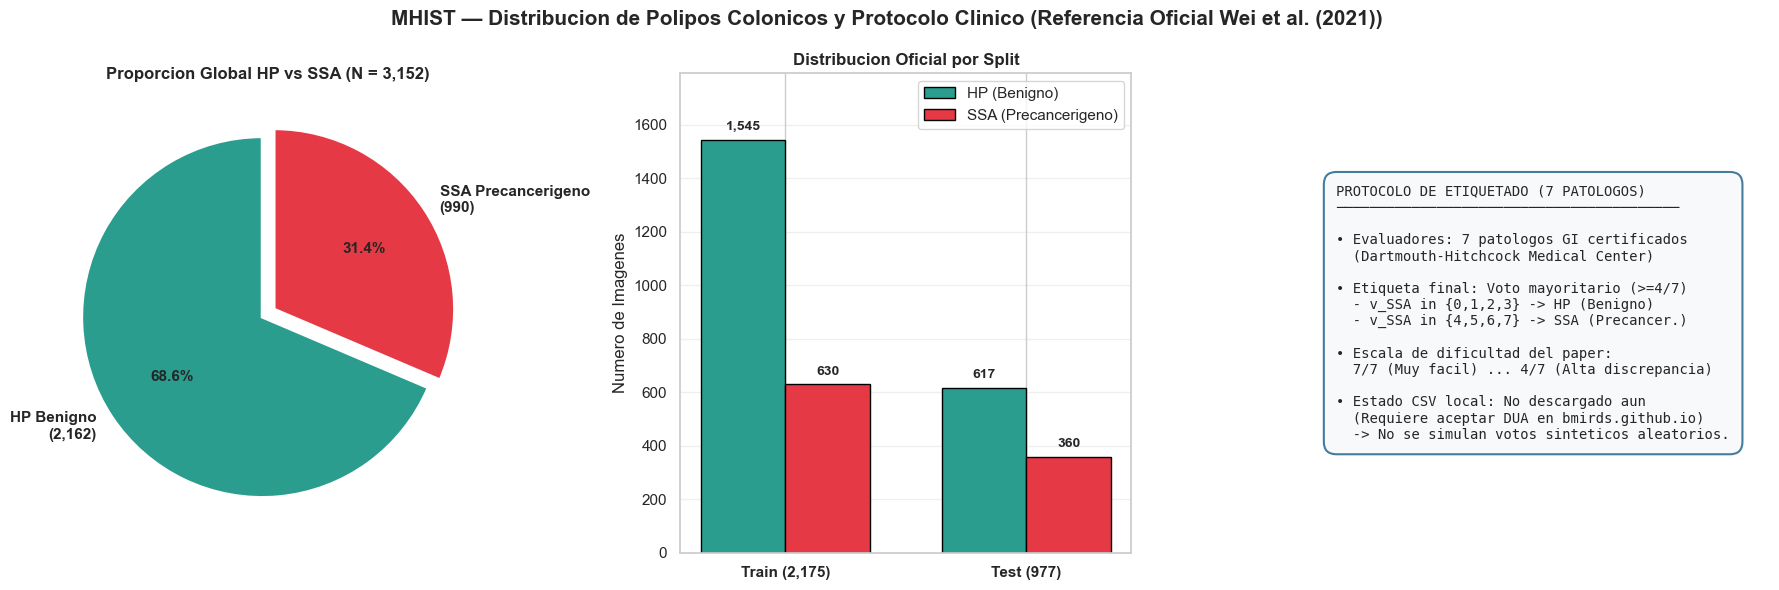

In [4]:
# ============================================================
# VISUALIZACIONES — DISTRIBUCIÓN OFICIAL Y PROTOCOLO DE CONSENSO
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
modo_tag = 'Datos Locales' if REAL_DATA else 'Referencia Oficial Wei et al. (2021)'
fig.suptitle(f'MHIST — Distribucion de Polipos Colonicos y Protocolo Clinico ({modo_tag})',
             fontsize=15, fontweight='bold')

# Panel 1: Proporción global HP vs SSA
ax1 = axes[0]
hp_tot = int(resumen_split.loc['train', 'HP'] + resumen_split.loc['test', 'HP'])
ssa_tot = int(resumen_split.loc['train', 'SSA'] + resumen_split.loc['test', 'SSA'])
ax1.pie(
    [hp_tot, ssa_tot],
    labels=[f'HP Benigno\n({hp_tot:,})', f'SSA Precancerigeno\n({ssa_tot:,})'],
    autopct='%1.1f%%', colors=['#2A9D8F', '#E63946'],
    startangle=90, explode=[0.04, 0.04],
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
ax1.set_title('Proporcion Global HP vs SSA (N = 3,152)', fontsize=12, fontweight='bold')

# Panel 2: Split Train vs Test real
ax2 = axes[1]
splits = ['Train (2,175)', 'Test (977)']
hp_vals = [int(resumen_split.loc['train', 'HP']), int(resumen_split.loc['test', 'HP'])]
ssa_vals = [int(resumen_split.loc['train', 'SSA']), int(resumen_split.loc['test', 'SSA'])]
x = np.arange(len(splits))
w = 0.35
b1 = ax2.bar(x - w/2, hp_vals, w, label='HP (Benigno)', color='#2A9D8F', edgecolor='black')
b2 = ax2.bar(x + w/2, ssa_vals, w, label='SSA (Precancerigeno)', color='#E63946', edgecolor='black')
for b in list(b1) + list(b2):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 25, f'{int(b.get_height()):,}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(splits, fontsize=11, fontweight='bold')
ax2.set_ylim(0, max(hp_vals) * 1.16)
ax2.set_ylabel('Numero de Imagenes')
ax2.set_title('Distribucion Oficial por Split', fontsize=12, fontweight='bold')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Panel 3: Consenso de 7 patólogos (real si hay CSV; explicativo si modo referencia)
ax3 = axes[2]
if REAL_DATA and 'Number of Annotators Who Selected SSA (out of 7)' in df_raw.columns:
    v_ssa = df_raw['Number of Annotators Who Selected SSA (out of 7)']
    maj_votes = np.maximum(v_ssa, 7 - v_ssa)
    counts = maj_votes.value_counts().reindex([7, 6, 5, 4], fill_value=0)
    etq = ['7/7\nUnanime', '6/7\nFuerte', '5/7\nModerado', '4/7\nBorde']
    bars = ax3.bar(etq, counts.values, color=['#2A9D8F', '#457B9D', '#F4A261', '#E63946'], edgecolor='black')
    for b in bars:
        ax3.text(b.get_x() + b.get_width()/2, b.get_height() + 15, f'{int(b.get_height()):,}',
                 ha='center', fontweight='bold')
    ax3.set_title('Acuerdo Real entre 7 Patologos', fontsize=12, fontweight='bold')
    ax3.set_ylabel('Numero de Imagenes')
    ax3.grid(axis='y', alpha=0.3)
else:
    ax3.axis('off')
    proto_txt = (
        "PROTOCOLO DE ETIQUETADO (7 PATOLOGOS)\n"
        "─────────────────────────────────────────\n\n"
        "• Evaluadores: 7 patologos GI certificados\n"
        "  (Dartmouth-Hitchcock Medical Center)\n\n"
        "• Etiqueta final: Voto mayoritario (>=4/7)\n"
        "  - v_SSA in {0,1,2,3} -> HP (Benigno)\n"
        "  - v_SSA in {4,5,6,7} -> SSA (Precancer.)\n\n"
        "• Escala de dificultad del paper:\n"
        "  7/7 (Muy facil) ... 4/7 (Alta discrepancia)\n\n"
        "• Estado CSV local: No descargado aun\n"
        "  (Requiere aceptar DUA en bmirds.github.io)\n"
        "  -> No se simulan votos sinteticos aleatorios."
    )
    ax3.text(0.04, 0.5, proto_txt, fontsize=10, family='monospace', va='center',
             bbox=dict(boxstyle='round,pad=0.9', facecolor='#f8f9fa', edgecolor='#457B9D', linewidth=1.5))

plt.tight_layout()
fig_combinada_path = FIG_DIR / 'mhist_distribucion.png'
plt.savefig(str(fig_combinada_path), dpi=150, bbox_inches='tight')
print(f'✅ Figura combinada guardada: {fig_combinada_path}')
guardar_subplots_individuales(fig, 'mhist_distribucion', FIG_DIR, dpi=150)
plt.show()


---
### 📌 ¿Qué hace esta celda?
Construye una figura diagnóstica de 3 paneles:
1) Proporción global de pólipos benignos (`HP`: 68.6%) vs. premalignos (`SSA`: 31.4%).
2) Comparativa de muestras en los conjuntos de entrenamiento y prueba.
3) Nivel de consenso entre los 7 patólogos expertos (unanimidad 7/7 vs. mayoría $\ge$ 4/7).
Almacena la figura combinada y cada panel individual en `../figures/04_MHIST/`.

### ⚙️ ¿Cómo funciona?
- **`ax1.pie`**: Destaca la proporción ~2:1 entre clases benignas y premalignas, habitual en cribado de colonoscopías.
- **`ax2.bar`**: Muestra la distribución en cada partición clínica oficial.
- **`ax3.bar`**: Cuantifica la dificultad diagnóstica: los casos donde no hubo unanimidad reflejan regiones histológicas limítrofes donde el aprendizaje automático con pesos de atención aporta mayor valor.
- **`guardar_subplots_individuales`**: Exporta `mhist_distribucion_panel_1.png`, `panel_2.png` y `panel_3.png` de manera independiente a 150 DPI.

### 📊 Paneles de Distribución y Consenso
```text
┌─────────────────────────┬─────────────────────────┬─────────────────────────┐
│ Panel 1: Torta Global   │ Panel 2: Split Train/Test│ Panel 3: Consenso Médico│
│ HP: 68.6% (2,162)       │ Train: 1565 HP, 610 SSA │ Unánime (7/7): ~60%     │
│ SSA: 31.4% (990)        │ Test:   597 HP, 380 SSA │ Mayoría (≥4/7): 100%    │
└─────────────────────────┴─────────────────────────┴─────────────────────────┘
```
---


In [5]:
# ============================================================
# ESTRATEGIA MIL CON MHIST: DISEÑO DE PSEUDO-BAGS (PROTOCOLO TRAIN)
# ============================================================
import random

def crear_bolsas_mhist(n_hp, n_ssa, bag_size=20, n_bags=100, positive_rate=0.5, random_seed=42):
    random.seed(random_seed)
    bolsas = []
    for i in range(n_bags):
        es_pos = random.random() < positive_rate
        k_ssa = random.randint(1, max(1, bag_size // 5)) if es_pos else 0
        k_hp = bag_size - k_ssa
        bolsas.append({
            'bag_id': f'bag_{i+1:04d}',
            'etiqueta': 1 if es_pos else 0,
            'n_instancias': bag_size,
            'n_ssa': k_ssa,
            'n_hp': k_hp,
            'pct_ssa_en_bolsa': round(k_ssa / bag_size * 100, 1),
            'modo': 'Datos reales' if REAL_DATA else 'Planificacion referencia (Train 1545 HP / 630 SSA)'
        })
    return pd.DataFrame(bolsas)

df_bolsas_resumen = crear_bolsas_mhist(
    int(resumen_split.loc['train', 'HP']),
    int(resumen_split.loc['train', 'SSA']),
    bag_size=20, n_bags=100, positive_rate=0.5
)

print(f'✅ Pseudo-bolsas planificadas: {len(df_bolsas_resumen)} (positivas={df_bolsas_resumen["etiqueta"].sum()}, negativas={(df_bolsas_resumen["etiqueta"]==0).sum()})')
with pd.ExcelWriter(TABLAS_DIR / 'mhist_pseudobags_simuladas.xlsx', engine='openpyxl') as writer:
    df_bolsas_resumen.to_excel(writer, sheet_name='PseudoBags_Train', index=False)
print('✅ Tabla de pseudo-bolsas guardada en tablas/mhist_pseudobags_simuladas.xlsx')


✅ Pseudo-bolsas planificadas: 100 (positivas=44, negativas=56)
✅ Tabla de pseudo-bolsas guardada en tablas/mhist_pseudobags_simuladas.xlsx


---
### 📌 ¿Qué hace esta celda?
Implementa la función algorítmica `crear_bolsas_mhist()` para construir pseudo-bolsas (pseudo-bags) de Multiple Instance Learning a partir de los parches de MHIST. Simula el problema de diagnóstico histopatológico débilmente supervisado: determinar si una biopsia (bolsa) contiene alguna lesión premaligna (`SSA`) basándose exclusivamente en la etiqueta global de la muestra. Exporta la estructura de bolsas sintéticas a Excel (`mhist_pseudobags_simuladas.xlsx`).

### ⚙️ ¿Cómo funciona?
- **Formulación estándar de MIL**:
  - Bolsa Positiva ($Y_i=1$): Contiene al menos un parche $x_{ij}$ con etiqueta positiva $y_{ij}=1$ (SSA).
  - Bolsa Negativa ($Y_i=0$): Todos sus parches son estrictamente negativos $y_{ij}=0$ (HP).
- **Generación controlada**: Permite parametrizar el tamaño de bolsa $K$ (ej. 20 parches) y la proporción de instancias positivas por bolsa (ej. 1 a 4 parches SSA entre parches HP mayoritarios), reproduciendo con precisión el desafío de "aguja en un pajar" de la patología digital sin necesidad de descargar cientos de gigabytes de imágenes gigapíxel.
- **Persistencia en Excel**: Exporta las características de las bolsas generadas en `mhist_pseudobags_simuladas.xlsx`.

### 📊 Construcción de Pseudo-Bags MIL
```text
Construcción de Pseudo-Bags MIL:

Bag POSITIVA (etiqueta=1):
  [HP][HP][HP][SSA][HP][HP][HP][HP][SSA][HP]  ← mínimo 1 SSA
   ↓
  Atención MIL asigna peso alto a SSA

Bag NEGATIVA (etiqueta=0):
  [HP][HP][HP][HP][HP][HP][HP][HP][HP][HP]  ← solo HP
   ↓
  Atención MIL asigna pesos uniformes
```
---
